# 04 · Predicción por etapas del semestre — de la primera nota al resultado

El riesgo no se conoce igual durante todo el semestre. Por eso se entrena un modelo por **etapa**, según cuántas notas de corte se conocen:

| Etapa | Se conoce | Predice |
|---|---|---|
| 0 | solo hábitos y contexto (alerta temprana) | riesgo, nota final, **primer corte** |
| 1 | + primer corte | riesgo, nota final, **segundo corte** |
| 2 | + segundo corte | riesgo, nota final |

Todo se trabaja en la **escala de referencia 0-5** (aprueba con 3.0). `src/calificacion.py` convierte desde cualquier otro esquema (0-10, 0-20, 0-100, letras, con cualquier número de cortes y pesos) conservando la nota aprobatoria.

Los mismos controles que en el notebook 03: partición por estudiante, GroupKFold dentro de train y Pipelines. Los datos son **sintéticos**. La sección 5 repite la prueba principal con un dataset **real** (UCI 320).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, f1_score, mean_absolute_error, precision_score,
                             r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict, cross_validate

from features import RAIZ, CAT, HABITOS, OBJETIVO, GRUPO, SEED
from modelo import NUM_ETAPA, construir, pipeline_kmeans, nombres_clusters

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
sel = json.loads((RAIZ / "models/seleccion.json").read_text())
print("Tipo de modelo elegido en 03:", sel)

df = pd.read_csv(RAIZ / "data/processed/registros_limpios.csv")
train, test = df[df.particion == "train"], df[df.particion == "test"]
ytr, yte, gtr = train[OBJETIVO], test[OBJETIVO], train[GRUPO]
cv = GroupKFold(n_splits=5)
SIGUIENTE = {0: "nota_corte1", 1: "nota_corte2"}  # corte que se predice en cada etapa
BASE_FINAL = {0: None, 1: "nota_corte1", 2: "promedio_cortes"}  # regla ingenua: "la nota sigue igual"

Tipo de modelo elegido en 03: {'tipo': 'hibrido', 'params': {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 20}}


## 1. Entrenamiento y validación por etapa
Se reutilizan los hiperparámetros elegidos con GroupKFold en el notebook 03. Para cada etapa se entrenan:
- un **clasificador** de riesgo;
- un **regresor** de la nota final;
- en las etapas 0 y 1, un **regresor del siguiente corte**.

Cada modelo se compara con una **regla ingenua** ("la nota final será igual al promedio de lo que llevas") para ver si aporta algo más que mirar la nota.

In [2]:
def m_clf(y, p, u=0.5):
    pr = (p >= u).astype(int)
    return {"pr_auc": average_precision_score(y, p), "roc_auc": roc_auc_score(y, p),
            "recall": recall_score(y, pr), "precision": precision_score(y, pr), "f1": f1_score(y, pr)}

def m_reg(y, p):
    return {"MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

etapas, filas_clf, filas_reg = {}, [], []
for e, num in NUM_ETAPA.items():
    feats = num + CAT
    Xtr, Xte = train[feats], test[feats]
    clf = construir(sel["tipo"], num).set_params(**sel["params"])
    p_cv = cross_val_predict(clf, Xtr, ytr, groups=gtr, cv=cv, method="predict_proba")[:, 1]
    clf.fit(Xtr, ytr); p_te = clf.predict_proba(Xte)[:, 1]
    filas_clf.append({"etapa": e, "conjunto": "CV train", **m_clf(ytr, p_cv)})
    filas_clf.append({"etapa": e, "conjunto": "test", **m_clf(yte, p_te)})
    if BASE_FINAL[e]:  # regla ingenua: menor nota => más riesgo
        filas_clf.append({"etapa": e, "conjunto": f"test · regla ({BASE_FINAL[e]} < 3)",
                          **m_clf(yte, -test[BASE_FINAL[e]].values, u=-3.0)})

    regs = {"nota_final": "nota_final", **({"siguiente": SIGUIENTE[e]} if e in SIGUIENTE else {})}
    modelos_reg = {}
    for nombre, objetivo in regs.items():
        reg = construir(sel["tipo"], num, regresion=True).set_params(**sel["params"])
        r_cv = cross_val_predict(reg, Xtr, train[objetivo], groups=gtr, cv=cv)
        reg.fit(Xtr, train[objetivo]); r_te = reg.predict(Xte)
        modelos_reg[nombre] = reg
        filas_reg.append({"etapa": e, "predice": objetivo, "conjunto": "CV train", **m_reg(train[objetivo], r_cv)})
        filas_reg.append({"etapa": e, "predice": objetivo, "conjunto": "test", **m_reg(test[objetivo], r_te)})
        base = test[BASE_FINAL[e]] if (nombre == "nota_final" and BASE_FINAL[e]) else \
               test["nota_corte1"] if objetivo == "nota_corte2" else pd.Series(train[objetivo].mean(), index=test.index)
        filas_reg.append({"etapa": e, "predice": objetivo, "conjunto": "test · regla ingenua", **m_reg(test[objetivo], base)})

    imp = permutation_importance(clf, Xte, yte, scoring="average_precision", n_repeats=10,
                                 random_state=SEED, n_jobs=1)
    etapas[e] = {"num": num, "features": feats, "clf": clf, "reg_final": modelos_reg["nota_final"],
                 "reg_siguiente": modelos_reg.get("siguiente"), "siguiente": SIGUIENTE.get(e),
                 "importancia": pd.Series(imp.importances_mean, index=feats).sort_values(ascending=False),
                 "pred_test": {"p": p_te, "final": modelos_reg["nota_final"].predict(Xte)}}
    print(f"etapa {e} lista")

tab_clf = pd.DataFrame(filas_clf).set_index(["etapa", "conjunto"])
tab_reg = pd.DataFrame(filas_reg).set_index(["etapa", "predice", "conjunto"])
tab_clf.round(3)

etapa 0 lista


etapa 1 lista


etapa 2 lista


pr_auc  roc_auc  recall  precision     f1
etapa conjunto                                                                     
0     CV train                             0.687    0.881   0.807      0.498  0.616
      test                                 0.670    0.872   0.824      0.502  0.624
1     CV train                             0.695    0.885   0.808      0.508  0.624
      test                                 0.663    0.876   0.824      0.510  0.630
      test · regla (nota_corte1 < 3)       0.473    0.795   0.532      0.484  0.507
2     CV train                             0.711    0.893   0.813      0.535  0.646
      test                                 0.675    0.884   0.820      0.524  0.640
      test · regla (promedio_cortes < 3)   0.597    0.853   0.552      0.570  0.561

In [3]:
tab_reg.round(3)

MAE     R2
etapa predice     conjunto                          
0     nota_final  CV train              0.429  0.528
                  test                  0.424  0.524
                  test · regla ingenua  0.616 -0.001
      nota_corte1 CV train              0.477  0.443
                  test                  0.463  0.442
                  test · regla ingenua  0.627 -0.000
1     nota_final  CV train              0.421  0.543
                  test                  0.422  0.532
                  test · regla ingenua  0.568  0.106
      nota_corte2 CV train              0.513  0.459
                  test                  0.490  0.451
                  test · regla ingenua  0.611  0.137
2     nota_final  CV train              0.405  0.578
                  test                  0.410  0.554
                  test · regla ingenua  0.471  0.398

**Cómo leer las tablas:** la PR-AUC de un clasificador al azar es ≈ 0,21. Una *regla ingenua* que el modelo no supera indica que, en esa etapa, el modelo no aporta más que mirar la nota.

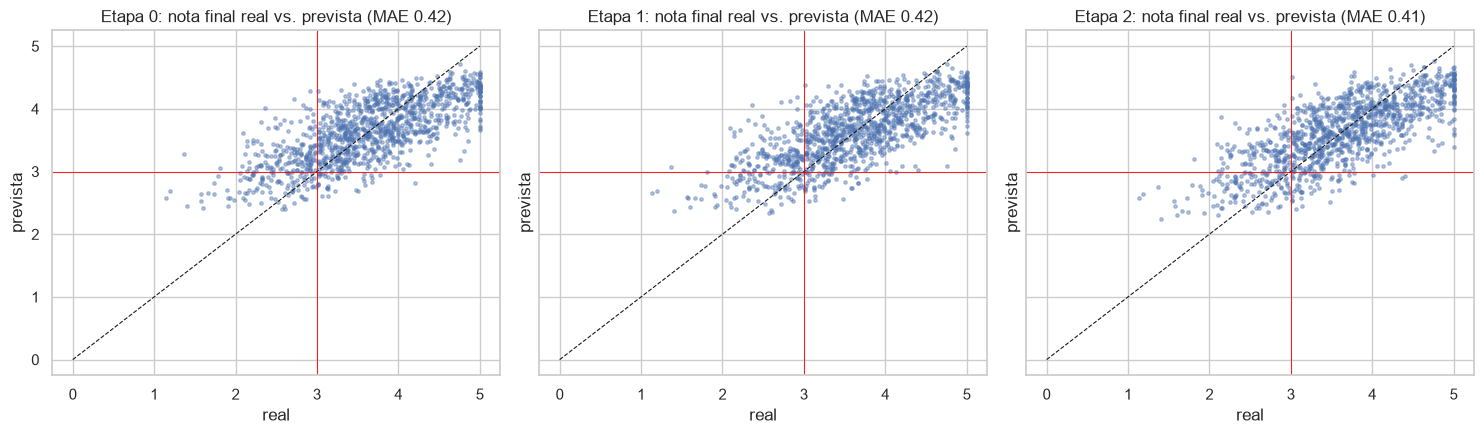

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, (e, d) in zip(axs, etapas.items()):
    ax.scatter(test.nota_final, d["pred_test"]["final"], s=6, alpha=0.4)
    ax.plot([0, 5], [0, 5], "k--", lw=0.8); ax.axhline(3, color="red", lw=0.6); ax.axvline(3, color="red", lw=0.6)
    mae = mean_absolute_error(test.nota_final, d["pred_test"]["final"])
    ax.set(title=f"Etapa {e}: nota final real vs. prevista (MAE {mae:.2f})", xlabel="real", ylabel="prevista")
plt.tight_layout(); plt.show()

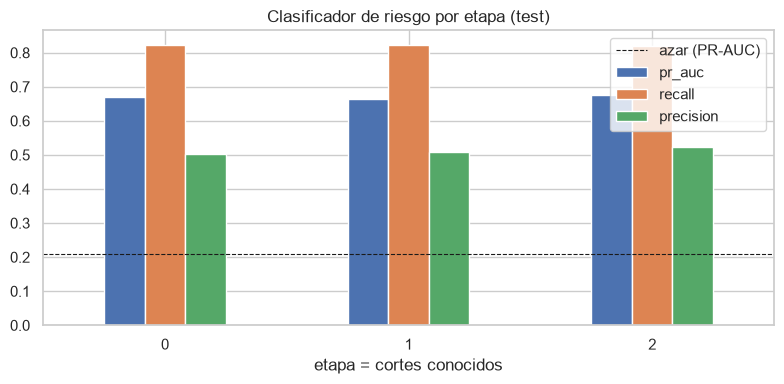

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
pr = tab_clf.xs("test", level="conjunto")[["pr_auc", "recall", "precision"]]
pr.plot.bar(ax=ax, rot=0); ax.axhline(yte.mean(), color="k", ls="--", lw=0.8, label="azar (PR-AUC)")
ax.set(title="Clasificador de riesgo por etapa (test)", xlabel="etapa = cortes conocidos"); ax.legend()
plt.tight_layout(); plt.show()

## 2. Variables más influyentes por etapa
Es la importancia por permutación en test (caída de la PR-AUC). `src/recomendar.py` usa estas importancias para decidir qué recomendar en cada etapa.

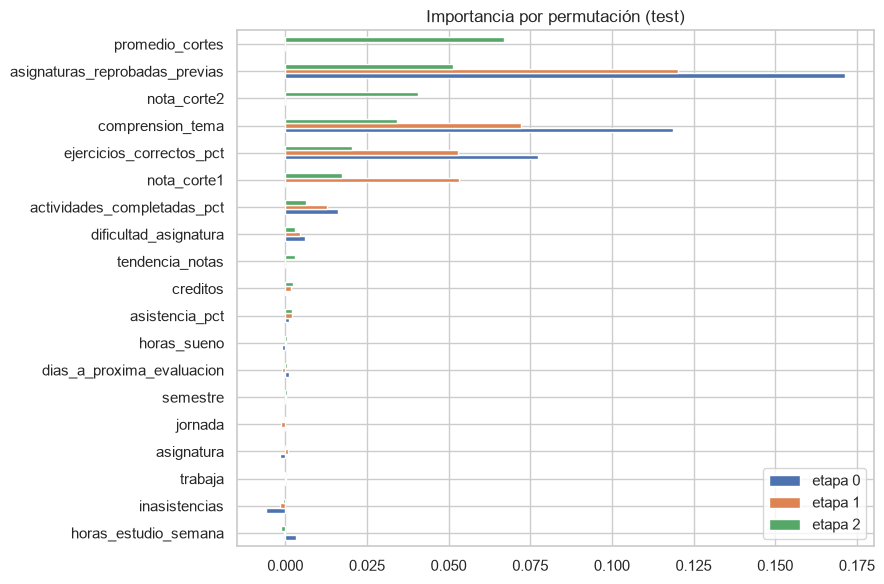

,etapa 0,etapa 1,etapa 2
promedio_cortes,NaN,NaN,0.0671
asignaturas_reprobadas_previas,0.1714,0.1203,0.0513
nota_corte2,NaN,NaN,0.0406
comprension_tema,0.1187,0.0723,0.0343
ejercicios_correctos_pct,0.0773,0.0529,0.0204
nota_corte1,NaN,0.0530,0.0175
actividades_completadas_pct,0.0162,0.0127,0.0064
dificultad_asignatura,0.0060,0.0044,0.0031
tendencia_notas,NaN,NaN,0.0030
creditos,0.0002,0.0019,0.0023


In [6]:
imp = pd.DataFrame({f"etapa {e}": d["importancia"] for e, d in etapas.items()})
imp = imp.sort_values("etapa 2", ascending=False)
fig, ax = plt.subplots(figsize=(9, 6)); imp.iloc[::-1].plot.barh(ax=ax)
ax.set_title("Importancia por permutación (test)"); plt.tight_layout(); plt.show()
imp.round(4)

## 3. Ejemplo: de una escala cualquiera a la predicción
Mismo estudiante en tres esquemas distintos. Como la conversión conserva la nota aprobatoria, un 2,4/5 equivale a 8,0/20 y a 48/100: en los tres casos está por debajo del aprobado.

In [7]:
from calificacion import ESQUEMAS
for nombre, nota in [("0-5 (3 cortes 30/30/40)", 2.4), ("0-20 (3 periodos, UCI)", 8.0), ("0-100 (25/25/50)", 48)]:
    print(f"{nombre:28s} nota {nota:>5} -> referencia {ESQUEMAS[nombre].a_ref(nota):.2f}")

0-5 (3 cortes 30/30/40)      nota   2.4 -> referencia 2.40
0-20 (3 periodos, UCI)       nota   8.0 -> referencia 2.40
0-100 (25/25/50)             nota    48 -> referencia 2.40


## 4. Paquete del modelo para `src/recomendar.py`

In [8]:
ACCIONABLES = ["ejercicios_correctos_pct", "comprension_tema", "actividades_completadas_pct",
               "asistencia_pct", "horas_estudio_semana"]
km_pipe = pipeline_kmeans().fit(train[HABITOS])
paquete = {
    "tipo": sel["tipo"], "params": sel["params"],
    "etapas": {e: {k: v for k, v in d.items() if k != "pred_test"} for e, d in etapas.items()},
    "kmeans": km_pipe, "nombres_clusters": nombres_clusters(km_pipe),
    "ref_train": train[ACCIONABLES].agg(["median", "std"]), "accionables": ACCIONABLES,
    "umbral_prob": 0.5,
}
(RAIZ / "models").mkdir(exist_ok=True)
joblib.dump(paquete, RAIZ / "models/modelo_riesgo.joblib", compress=3)
(RAIZ / "reports").mkdir(exist_ok=True)
tab_clf.round(4).to_csv(RAIZ / "reports/etapas_clasificacion.csv")
tab_reg.round(4).to_csv(RAIZ / "reports/etapas_regresion.csv")
print("Guardado models/modelo_riesgo.joblib",
      f"({(RAIZ / 'models/modelo_riesgo.joblib').stat().st_size / 1e6:.1f} MB)")

Guardado models/modelo_riesgo.joblib (12.0 MB)


## 5. Prueba con datos reales: UCI Student Performance (id 320)
Son 649 estudiantes reales de secundaria en Portugal (curso de portugués), con G1, G2 y G3 en escala 0-20. G3 es la nota final y se aprueba con 10. Hay una fila por estudiante, así que basta con KFold.

La pregunta es: **¿la primera nota (G1) permite predecir G2 y G3?** Se compara un RF que usa notas + hábitos y contexto (`studytime`, `failures`, `absences`, etc.) con la regla ingenua "la siguiente nota será igual a la última".

Es una población distinta (secundaria, otro país), así que sirve como evidencia complementaria y no como validación del sistema universitario.

In [9]:
uci = pd.read_csv(RAIZ / "data/raw/student_performance.csv")
print(uci.shape, "| G3 == 0:", int((uci.G3 == 0).sum()), "| riesgo (G3 < 10):", round((uci.G3 < 10).mean(), 3))
ctx = pd.get_dummies(uci.drop(columns=["G1", "G2", "G3"]), drop_first=True).astype(float)
kf = KFold(5, shuffle=True, random_state=SEED)
rf_uci = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
casos = [("G1 -> G2", ["G1"], "G2", "G1"), ("G1 -> G3", ["G1"], "G3", "G1"), ("G1+G2 -> G3", ["G1", "G2"], "G3", "G2")]
filas = []
for nombre, notas, obj, ultima in casos:
    X = pd.concat([uci[notas], ctx], axis=1)
    p = cross_val_predict(rf_uci, X, uci[obj], cv=kf)
    p_solo = cross_val_predict(rf_uci, uci[notas], uci[obj], cv=kf)
    for modelo, pred in [("RF notas + contexto", p), ("RF solo notas", p_solo), ("regla: igual a la última", uci[ultima])]:
        riesgo_real = (uci[obj] < 10).astype(int)
        filas.append({"caso": nombre, "modelo": modelo, **m_reg(uci[obj], pred),
                      "recall_riesgo": recall_score(riesgo_real, (pred < 10).astype(int)),
                      "precision_riesgo": precision_score(riesgo_real, (pred < 10).astype(int), zero_division=0)})
uci_tab = pd.DataFrame(filas).set_index(["caso", "modelo"])
uci_tab.to_csv(RAIZ / "reports/uci320_prediccion_cortes.csv")
uci_tab.round(3)

(649, 33) | G3 == 0: 15 | riesgo (G3 < 10): 0.154


MAE     R2  recall_riesgo  precision_riesgo
caso        modelo                                                                 
G1 -> G2    RF notas + contexto       1.074  0.735          0.779             0.635
            RF solo notas             1.029  0.746          0.738             0.682
            regla: igual a la última  1.018  0.739          0.738             0.682
G1 -> G3    RF notas + contexto       1.196  0.711          0.840             0.583
            RF solo notas             1.220  0.677          0.880             0.561
            regla: igual a la última  1.247  0.658          0.880             0.561
G1+G2 -> G3 RF notas + contexto       0.795  0.849          0.900             0.596
            RF solo notas             0.830  0.830          0.900             0.608
            regla: igual a la última  0.767  0.833          0.890             0.614

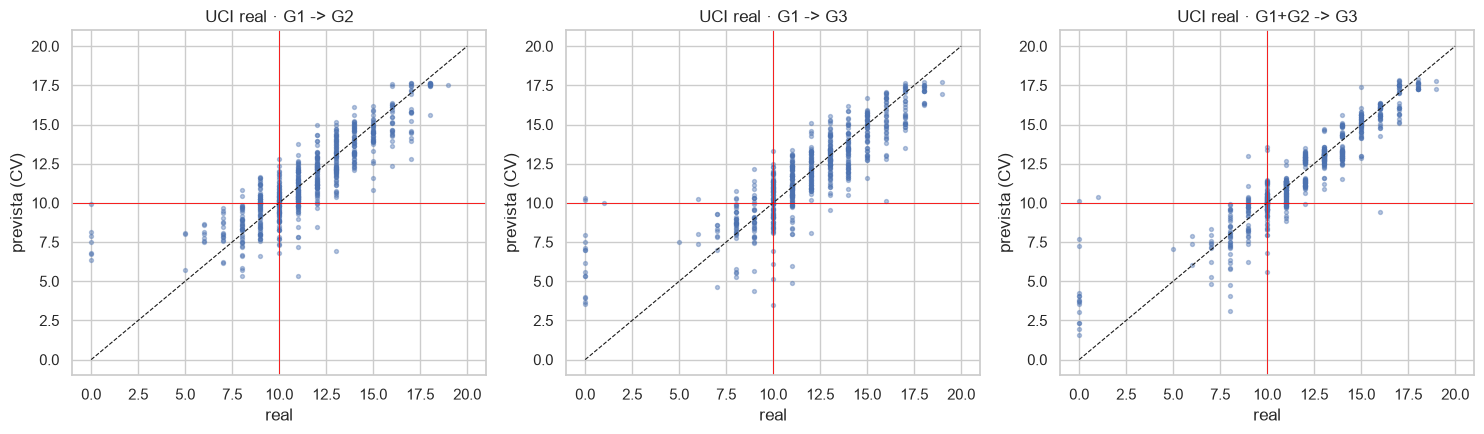

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nombre, notas, obj, _) in zip(axs, casos):
    p = cross_val_predict(rf_uci, pd.concat([uci[notas], ctx], axis=1), uci[obj], cv=kf)
    ax.scatter(uci[obj], p, s=8, alpha=0.4); ax.plot([0, 20], [0, 20], "k--", lw=0.8)
    ax.axhline(10, color="red", lw=0.6); ax.axvline(10, color="red", lw=0.6)
    ax.set(title=f"UCI real · {nombre}", xlabel="real", ylabel="prevista (CV)")
plt.tight_layout(); plt.show()